# NN experiment ? load or extend individual methods (_new_v2)

This is a separate companion to `experiment_nn_lipschitz_constraint_new.ipynb`. It uses the **same network, finite-power objective, full derivatives, damping, acceptance tests and solvers**. The existing notebooks and saved runs are preserved.

The default input is the named **paper run** in `corrected_results/paper_run/`: **Adam has 200,000 updates**, GLAd m = 200 has 5,000, m = 400 has 6,000, and m = 1, 20, 50, 100 retain 3,000 each. This is a separate verified copy of `new_v2/20261106_153005_814646/`, including the saved figures. `run_info.json` records the source, update counts and file hashes. The timestamped source remains available.

Each method cell has its own `ACTION`, `TOTAL_UPDATES`, and optional `SOURCE_FILE`:

| Action | Behaviour |
|---|---|
| `load` | Load that method from `SOURCE_FILE` or `BASE_RUN`. No training. |
| `continue` | Extend its current result (or load it first) to `TOTAL_UPDATES`. |
| `run` | Start that method from the saved common original initialization. |
| `skip` | Do nothing; retain any result already loaded in this session. |

To keep **m = 1, 50, 100**, leave their cells on `load`. To extend a method, choose `continue` and set `TOTAL_UPDATES` above its saved count. For example, Adam at 210,000 means 10,000 additional updates from the paper run. Rerunning a continuation cell whose target is already reached does nothing. Loading this named run never overwrites it: future exports still use a separate timestamped folder under `corrected_results/new_v2/`.

The paper relationship is unchanged: local manuscript 2026-10-22, Algorithm 1, equation (26), Section 5.1 / Appendix E.1; [public arXiv v1](https://arxiv.org/abs/2602.08069v1) uses equation (27) and older settings. The input-Hessian norm is a finite-power estimate, not an exact global constraint. See `CORRECTIONS.md` and `../THIRD_PARTY.txt`.

**Load the paper run:** execute the first code cell to restore all saved histories, model weights and available optimizer checkpoints immediately. You can then run the plotting cells directly. Every method cell is set to `ACTION = "load"`, so Run All does not retrain. The saved Adam run has 200,000 updates; m = 200 has 5,000 and m = 400 has 6,000. To deliberately train further, change only the selected method cell to `continue` and choose a larger total. Rerunning setup reloads the saved paper snapshot; future results are still exported to a separate timestamped directory.


In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"  # Existing Windows workaround.

import sys
from pathlib import Path
import torch
import matplotlib.pyplot as plt
from matplotlib.ticker import SymmetricalLogLocator
from IPython.display import Markdown, display

sys.dont_write_bytecode = True
NN_DIR = Path.cwd()
if not (NN_DIR / "nn_run_manager_new_v2.py").exists():
    NN_DIR = NN_DIR / "NN"
NN_DIR = NN_DIR.resolve()
sys.path.insert(0, str(NN_DIR.parent))
from NN.nn_run_manager_new_v2 import RunManager

# Change this to a later nn_results_new_v2.pkl to resume after a kernel restart.
# Named paper run: Adam 200,000; m=200 5,000; m=400 6,000; other methods 3,000 updates.
BASE_RUN = NN_DIR / "corrected_results/paper_run/nn_results_new_v2.pkl"
ORIGINAL_RUN = NN_DIR / "corrected_results/20261106_091314_772492/nn_results_new.pkl"
OUTPUT_ROOT = NN_DIR / "corrected_results/new_v2"
CHECKPOINT_EVERY = 100  # Accepted updates; full optimizer state saved automatically.
PRINT_EVERY = 100
SAVE_RESULTS = True
SAVE_FIGURES = True

# Restore the complete named paper run. No training is performed here.
# Rerunning this cell reloads the saved snapshot into the active comparison.
runs = RunManager(BASE_RUN, OUTPUT_ROOT, CHECKPOINT_EVERY, PRINT_EVERY)
for saved_label in runs.base["labels"]:
    runs.load(saved_label)
print("Input:", BASE_RUN)
print("Saved budgets:", {label: info["accepted_steps"] for label, info in runs.base["statuses"].items()})
print("Fixed objective: K =", runs.metadata["K"],
      "epsilon =", runs.metadata["normalization_eps"],
      "coefficient =", runs.metadata["penalty_coefficient"])
print("Paper run restored: all saved methods are ready for plotting. Method cells default to load only.")
print("Full optimizer checkpoints available:", list(runs.base.get("checkpoints", {})))

Loaded Adam: 200,000 updates, gradient 1.518e-02
Loaded GLAd-SSN: 3,000 updates, gradient 7.199e-04
Loaded GLAd-SSN m=20: 3,000 updates, gradient 8.001e-04
Loaded GLAd-SSN m=50: 3,000 updates, gradient 4.155e-04
Loaded GLAd-SSN m=100: 3,000 updates, gradient 4.550e-04
Loaded GLAd-SSN m=200: 5,000 updates, gradient 3.906e-04
Loaded GLAd-SSN m=400: 6,000 updates, gradient 5.755e-04
Input: C:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\NN\corrected_results\paper_run\nn_results_new_v2.pkl
Saved budgets: {'Adam': 200000, 'GLAd-SSN': 3000, 'GLAd-SSN m=20': 3000, 'GLAd-SSN m=50': 3000, 'GLAd-SSN m=100': 3000, 'GLAd-SSN m=200': 5000, 'GLAd-SSN m=400': 6000}
Fixed objective: K = 10 epsilon = 1e-07 coefficient = 1
Paper run restored: all saved methods are ready for plotting. Method cells default to load only.
Full optimizer checkpoints available: ['Adam', 'GLAd-SSN m=200', 'GLAd-SSN m=400']


## Continuation and saved state

The old export saved model weights and histories, but **not optimizer state**. Adam needs its moments and learning-rate scheduler; GLAd needs its coefficient and cached Hessian with the correct reuse counter. In the original 3,000-update export, m = 400 was halfway through the Hessian block that began at 2,800.

**The paper run has full continuation states for Adam, m = 200 and m = 400:** they resume directly, without replay. Their extended histories preserve the earlier trajectory and include the subsequently computed updates. The other methods retain their saved original results.

If you select the original legacy file instead: on the **first continuation of a legacy file**, the helper replays only that method from its saved initialization and requires an **exact match of the final weights** before continuing. This costs a few minutes for Adam or m = 400 on the original machine; it does not rerun m = 1. At a GLAd refresh boundary, no replay is needed. New `_v2` checkpoints contain the full state and resume directly.

Training saves a new result file before extra updates, every `CHECKPOINT_EVERY` accepted updates, on completion, and on an ordinary kernel interrupt. A kernel/process crash can lose updates since the last checkpoint. All results go to a new timestamped directory under `corrected_results/new_v2/`. To resume later, set `BASE_RUN` to the printed `nn_results_new_v2.pkl` path.

The saved data, initial weights, K, epsilon, penalty, precision and solver settings remain fixed across the comparison. Loading a different method file checks compatibility. Changing epsilon or K requires a separate comparison because it changes the objective. Recovery time is recorded in provenance. Recovery, checkpoint I/O and checkpoint-copy overhead are excluded from the continuation's plotted training time; the original stored timing is retained.

## Adam ? extend independently

In [2]:
ACTION = "load"  # "load", "continue", "run", or "skip"
TOTAL_UPDATES = 200000  # Total accepted updates, including the loaded history.
SOURCE_FILE = None  # Optional Path to another compatible result file.
runs.choose('Adam', action=ACTION, total_updates=TOTAL_UPDATES, source=SOURCE_FILE)

Loaded Adam: 200,000 updates, gradient 1.518e-02


## GLAd-SSN, m = 1 ? keep the expensive saved run

In [3]:
ACTION = "load"  # "load", "continue", "run", or "skip"
TOTAL_UPDATES = 3000  # Total accepted updates, including the loaded history.
SOURCE_FILE = None  # Optional Path to another compatible result file.
runs.choose('GLAd-SSN', action=ACTION, total_updates=TOTAL_UPDATES, source=SOURCE_FILE)

Loaded GLAd-SSN: 3,000 updates, gradient 7.199e-04


## GLAd-SSN, m = 20

In [4]:
ACTION = "load"  # "load", "continue", "run", or "skip"
TOTAL_UPDATES = 3000  # Total accepted updates, including the loaded history.
SOURCE_FILE = None  # Optional Path to another compatible result file.
runs.choose('GLAd-SSN m=20', action=ACTION, total_updates=TOTAL_UPDATES, source=SOURCE_FILE)

Loaded GLAd-SSN m=20: 3,000 updates, gradient 8.001e-04


## GLAd-SSN, m = 50

In [5]:
ACTION = "load"  # "load", "continue", "run", or "skip"
TOTAL_UPDATES = 3000  # Total accepted updates, including the loaded history.
SOURCE_FILE = None  # Optional Path to another compatible result file.
runs.choose('GLAd-SSN m=50', action=ACTION, total_updates=TOTAL_UPDATES, source=SOURCE_FILE)

Loaded GLAd-SSN m=50: 3,000 updates, gradient 4.155e-04


## GLAd-SSN, m = 100

In [6]:
ACTION = "load"  # "load", "continue", "run", or "skip"
TOTAL_UPDATES = 3000  # Total accepted updates, including the loaded history.
SOURCE_FILE = None  # Optional Path to another compatible result file.
runs.choose('GLAd-SSN m=100', action=ACTION, total_updates=TOTAL_UPDATES, source=SOURCE_FILE)

Loaded GLAd-SSN m=100: 3,000 updates, gradient 4.550e-04


## GLAd-SSN, m = 200

In [7]:
ACTION = "load"  # "load", "continue", "run", or "skip"
TOTAL_UPDATES = 5000  # Total accepted updates, including the loaded history.
SOURCE_FILE = None  # Optional Path to another compatible result file.
runs.choose('GLAd-SSN m=200', action=ACTION, total_updates=TOTAL_UPDATES, source=SOURCE_FILE)

Loaded GLAd-SSN m=200: 5,000 updates, gradient 3.906e-04


## GLAd-SSN, m = 400 ? extend independently

In [8]:
ACTION = "load"  # "load", "continue", "run", or "skip"
TOTAL_UPDATES = 6000  # Total accepted updates, including the loaded history.
SOURCE_FILE = None  # Optional Path to another compatible result file.
runs.choose('GLAd-SSN m=400', action=ACTION, total_updates=TOTAL_UPDATES, source=SOURCE_FILE)

Loaded GLAd-SSN m=400: 6,000 updates, gradient 5.755e-04


## Review and save the selected comparison

The original histories remain unchanged when loaded. Continued histories retain every original point and append new points without repeating the join. Every export includes per-method update counts, weights, histories, settings, source files, and any available full optimizer checkpoints. Loaded legacy methods remain loadable without having to reconstruct their optimizer states.

In [9]:
rows = ["| Method | Updates | Loss | Gradient norm | Runtime (min) | Status |",
        "|---|---:|---:|---:|---:|---|"]
for label, record in runs.records.items():
    h, info = record["history"], record["info"]
    rows.append(f"| {label} | {info['accepted_steps']:,} | {h['loss'][-1]:.6g} | "
                f"{h['grad_norm'][-1]:.3e} | {h['time'][-1] / 60:.2f} | {info['status']} |")
display(Markdown("\n".join(rows)))
if SAVE_RESULTS:
    RESULT_FILE = runs.save()
    print("For a later session, use this as BASE_RUN:", RESULT_FILE)

| Method | Updates | Loss | Gradient norm | Runtime (min) | Status |
|---|---:|---:|---:|---:|---|
| Adam | 200,000 | 0.0139889 | 1.518e-02 | 68.55 | iterations_exceeded |
| GLAd-SSN | 3,000 | 0.00462285 | 7.199e-04 | 220.38 | iterations_exceeded |
| GLAd-SSN m=20 | 3,000 | 0.0045712 | 8.001e-04 | 12.53 | iterations_exceeded |
| GLAd-SSN m=50 | 3,000 | 0.00477319 | 4.155e-04 | 6.00 | iterations_exceeded |
| GLAd-SSN m=100 | 3,000 | 0.00514182 | 4.550e-04 | 3.88 | iterations_exceeded |
| GLAd-SSN m=200 | 5,000 | 0.00493811 | 3.906e-04 | 5.09 | iterations_exceeded |
| GLAd-SSN m=400 | 6,000 | 0.00516234 | 5.755e-04 | 5.08 | iterations_exceeded |

Saved: C:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\NN\corrected_results\new_v2\20261106_183747_522364\nn_results_new_v2.pkl
For a later session, use this as BASE_RUN: C:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\NN\corrected_results\new_v2\20261106_183747_522364\nn_results_new_v2.pkl


## Paper-style plots

Select the methods independently of the training cells. The first panel shows cumulative runtime, the second accepted updates. Both panels have matching major and minor grid lines; the original plotting cell only enabled a grid on the left. Initial points and exact zero gradients remain visible using the same symlog scales.

Figures use new `_new_v2` filenames in this session's output directory. Rerunning this cell updates only those new figures.

**Line width and colors:** edit `PLOT_LINEWIDTH` (points) at the start of the next cell to change all method curves in the gradient, sampled-Hessian-norm and loss plots. The default `2.5` matches `MF/experiment_matrix_factorization.ipynb`; the NN curves previously used `1`. Edit `known_styles` below it for individual colors and markers: m = 100 uses the original light blue (`#8DCBE4`), and m = 50 uses a stronger green (`#2CA02C`). Rerun this plotting cell and the later plots to apply changes; training does not need to run.

**Markers:** `PLOT_MARKERSIZE = 5` sets marker size in points. `PLOT_MARKER_SPACING = 0.15` uses the display-distance spacing from the final parallel MF notebook: smaller positive floats show more markers along each curve, including on logarithmic axes. Both panels and the sampled-Hessian-norm plot use the shapes in `known_styles`; Adam remains a plain line. This replaces the old 15,000-update spacing, which left most NN curves with only an initial marker. All recorded data points are still plotted.

**Plot limits:** edit `PLOT_MAX_TIME` (seconds) and `PLOT_MAX_ITERATIONS` (accepted updates) at the start of the next cell. For example, `600` and `5000` show up to 10 minutes and 5,000 updates. `None` uses the full recorded range. These limits apply to the gradient plot and the loss plot at the end; the iteration limit also applies to the sampled-Hessian-norm plot. They only change the displayed axes, not the saved data or `TOTAL_UPDATES` training budgets. Rerun this plotting cell and whichever later plots you want to update; training cells do not need to run.


Saved: C:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\NN\corrected_results\new_v2\20261106_183747_522364\plot_NN_new_v2_grad_norm.pdf


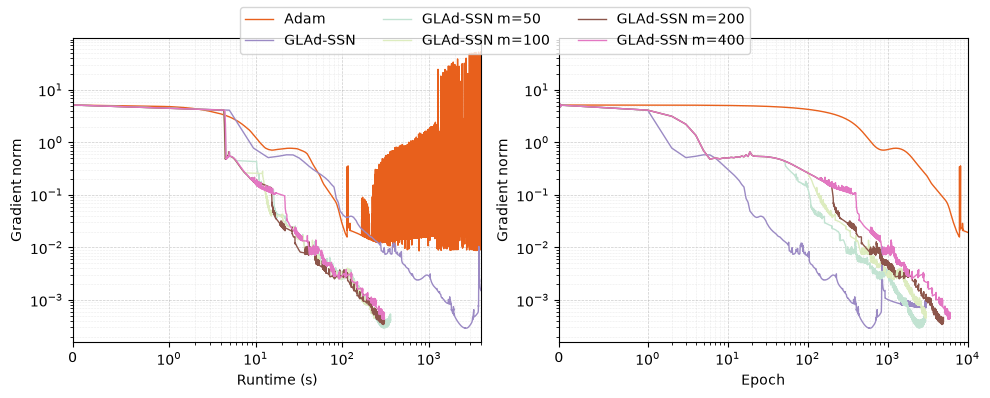

In [23]:
PLOT_METHODS = ["Adam", "GLAd-SSN", "GLAd-SSN m=50", "GLAd-SSN m=100", "GLAd-SSN m=200", "GLAd-SSN m=400"]
# Use list(runs.records) to show every loaded method.
# Display limits shared by the gradient, sampled-norm and loss plots.
# None shows the complete saved history; these do not change training budgets.
PLOT_MAX_TIME = 4000        # Runtime in seconds, e.g. 600 for 10 minutes.
PLOT_MAX_ITERATIONS = 10000  # Accepted updates, e.g. 5000.
PLOT_LINEWIDTH = 2.5       # Curve width in points; matches the original MF example.
PLOT_MARKERSIZE = 5        # Marker size in points; matches the MF example.
PLOT_MARKER_SPACING = 0.15 # Display-distance spacing; smaller floats add more markers.
for value in (PLOT_MAX_TIME, PLOT_MAX_ITERATIONS):
    if value is not None and not (0 < float(value) < float("inf")):
        raise ValueError("Plot limits must be positive finite numbers or None.")
labels = [label for label in PLOT_METHODS if label in runs.records]
if not labels:
    raise ValueError("Load or run at least one selected method before plotting.")

known_styles = {
    "Adam": ("#E8601C", "None"), "GLAd-SSN": ("#9B8AC4", "^"),
    "GLAd-SSN m=20": ("#8DCBE4", "x"), "GLAd-SSN m=50": ("#2CA02C", "v"),
    "GLAd-SSN m=100": ("#8DCBE4", "h"), "GLAd-SSN m=200": ("#8C564B", "o"),
    "GLAd-SSN m=400": ("#E377C2", "o"),
}

fig_gradient, axes = plt.subplots(1, 2, figsize=(10, 4))
for label in labels:
    history = runs.records[label]["history"]
    color, marker = known_styles.get(label, ("black", "o"))
    axes[0].plot(history["time"], history["grad_norm"], label=label, color=color, linewidth=PLOT_LINEWIDTH,
                 marker=marker, markersize=PLOT_MARKERSIZE, markevery=PLOT_MARKER_SPACING)
    axes[1].plot(history["grad_norm"], label=label, color=color, linewidth=PLOT_LINEWIDTH,
                 marker=marker, markersize=PLOT_MARKERSIZE, markevery=PLOT_MARKER_SPACING)
for ax in axes:
    ax.set_yscale("symlog", linthresh=1e-12)
    ax.set_xscale("symlog", linthresh=1)
    ax.set_ylabel("Gradient norm")
    ax.xaxis.set_minor_locator(SymmetricalLogLocator(base=10, linthresh=1, subs=range(2, 10)))
    ax.yaxis.set_minor_locator(SymmetricalLogLocator(base=10, linthresh=1e-12, subs=range(2, 10)))
    ax.set_axisbelow(True)
    ax.grid(True, which="major", linestyle="--", linewidth=0.5, alpha=0.65)
    ax.grid(True, which="minor", linestyle="--", linewidth=0.4, alpha=0.25)
axes[0].set_xlabel("Runtime (s)")
axes[1].set_xlabel("Epoch")
axes[0].set_xlim(0, PLOT_MAX_TIME if PLOT_MAX_TIME is not None else max(1, max(runs.records[label]["history"]["time"][-1] for label in labels)))
axes[1].set_xlim(0, PLOT_MAX_ITERATIONS if PLOT_MAX_ITERATIONS is not None else max(1, max(runs.records[label]["info"]["accepted_steps"] for label in labels)))
handles, legend_labels = axes[0].get_legend_handles_labels()
fig_gradient.legend(handles, legend_labels, loc="upper center", ncol=3)
fig_gradient.tight_layout(rect=[0, 0, 1, 0.95])
if SAVE_FIGURES:
    figure_file = runs.directory() / "plot_NN_new_v2_grad_norm.pdf"
    fig_gradient.savefig(figure_file)
    print("Saved:", figure_file)
plt.show()

Saved: C:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\NN\corrected_results\new_v2\20261106_183747_522364\plot_NN_new_v2_hess_op_norm.pdf


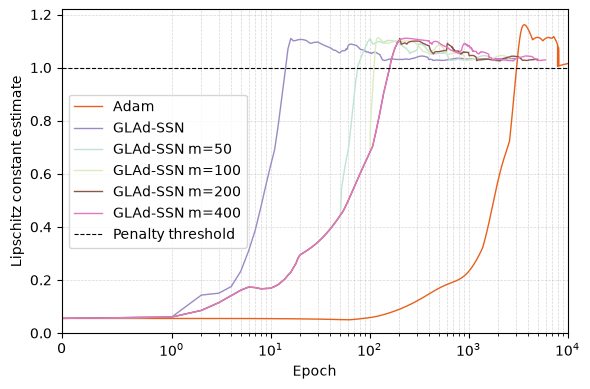

In [21]:
# The same PLOT_METHODS selection is used for the sampled input-Hessian norms.
fig_norm, ax = plt.subplots(figsize=(6, 4))
for label in labels:
    history = runs.records[label]["history"]
    color, marker = known_styles.get(label, ("black", "o"))
    ax.plot(history["hessian_norm"], label=label, color=color, linewidth=PLOT_LINEWIDTH,
            marker=marker, markersize=PLOT_MARKERSIZE, markevery=PLOT_MARKER_SPACING)
ax.set_xscale("symlog", linthresh=1)
ax.xaxis.set_minor_locator(SymmetricalLogLocator(base=10, linthresh=1, subs=range(2, 10)))
ax.set_xlim(0, PLOT_MAX_ITERATIONS if PLOT_MAX_ITERATIONS is not None else max(1, max(runs.records[label]["info"]["accepted_steps"] for label in labels)))
ax.set_ylim(0, 1.05 * max(1.0, max(max(runs.records[label]["history"]["hessian_norm"]) for label in labels)))
ax.axhline(1.0, color="black", linestyle="--", linewidth=0.8, label="Penalty threshold")
ax.set_xlabel("Epoch")
ax.set_ylabel("Lipschitz constant estimate")
ax.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.5)
ax.legend()
fig_norm.tight_layout()
if SAVE_FIGURES:
    figure_file = runs.directory() / "plot_NN_new_v2_hess_op_norm.pdf"
    fig_norm.savefig(figure_file)
    print("Saved:", figure_file)
plt.show()

## Train/test MSE and common gradient targets

These cells evaluate only the selected saved models; they do not train. Target times are the first recorded crossings, without interpolation. They refer to the same finite-power objective.

In [16]:
rows = ["| Method | Training MSE | Test MSE |", "|---|---:|---:|"]
test_X = torch.stack([x for x, y in runs.test_dataset])
test_Y = torch.stack([y for x, y in runs.test_dataset])
from NN.nn_run_manager_new_v2 import Net
for label in labels:
    model = Net(dtype=runs.dtype)
    model.load_state_dict(runs.records[label]["weights"])
    with torch.no_grad():
        train_mse = (model(runs.X) - runs.Y).square().mean().item()
        test_mse = (model(test_X) - test_Y).square().mean().item()
    rows.append(f"| {label} | {train_mse:.6g} | {test_mse:.6g} |")
display(Markdown("\n".join(rows)))

targets = runs.metadata.get("gradient_targets", [1e-2, 1e-3, 1e-4])
rows = ["| Method | " + " | ".join(f"{t:.0e}" for t in targets) + " |",
        "|---|" + "---|" * len(targets)]
for label in labels:
    h = runs.records[label]["history"]
    entries = []
    for target in targets:
        hit = next((i for i, g in enumerate(h["grad_norm"]) if g <= target), None)
        entries.append("not reached" if hit is None else f"{hit:,} updates / {h['time'][hit]:.2f} s")
    rows.append("| " + label + " | " + " | ".join(entries) + " |")
display(Markdown("\n".join(rows)))

| Method | Training MSE | Test MSE |
|---|---:|---:|
| Adam | 0.0138971 | 0.0314412 |
| GLAd-SSN | 0.00453803 | 0.0133977 |
| GLAd-SSN m=50 | 0.00468867 | 0.0137373 |
| GLAd-SSN m=100 | 0.0050522 | 0.014365 |
| GLAd-SSN m=200 | 0.0048535 | 0.0141692 |
| GLAd-SSN m=400 | 0.00506888 | 0.0143734 |

| Method | 1e-02 | 1e-03 | 1e-04 |
|---|---|---|---|
| Adam | 34,857 updates / 526.67 s | not reached | not reached |
| GLAd-SSN | 59 updates / 280.93 s | 334 updates / 1490.87 s | not reached |
| GLAd-SSN m=50 | 301 updates / 40.92 s | 1,446 updates / 174.22 s | not reached |
| GLAd-SSN m=100 | 445 updates / 36.55 s | 2,156 updates / 168.18 s | not reached |
| GLAd-SSN m=200 | 532 updates / 30.39 s | 3,001 updates / 172.49 s | not reached |
| GLAd-SSN m=400 | 844 updates / 40.80 s | 4,401 updates / 215.42 s | not reached |

## Validation and reproducibility notes

- Validated with Python 3.12.14, PyTorch 2.7.1+cu126 on CPU, float64, one thread. The saved comparison uses the actual float32-generated data/initialization promoted to float64, seeds 26/27, K = 10, epsilon = 1e-7, and penalty coefficient 1.
- `test_nn_resume_new_v2.py` checks exact equality of split versus uninterrupted Adam/GLAd runs, including a split inside a reused-Hessian block; legacy state recovery; rejection of mismatched endpoints and objectives; load-only behaviour; interruption rollback; and cumulative-budget reruns. These are small workflow checks, not full paper reproduction.
- Recovered the real legacy m = 400 state by replaying its 3,000 updates (about 111 seconds), and Adam's 25,000 updates (about 180 seconds). Both reproduced their final weights **bit for bit**. No new training updates were added to the prepared default checkpoint. The m = 1, 20, 50, 100 and 200 trajectories were only loaded.
- A separate two-update continuation check on the actual checkpoints verified Adam at 25,002 updates and m = 400 at 3,002, retaining its original cached Hessian (eight Hessian evaluations, reuse counter 202). These smoke-test outputs are separate from the prepared 25,000/3,000 checkpoint used for those checks; the named paper run contains the later extended results.
- Original result SHA256: `84738a20f9ed36f0545125c876ba9c8d8a1764099354774ac9819a73e6e5653d`. The original result, notebooks, optimizer and penalty helper were not edited by this update.
- Fresh-kernel load-only execution and PNG visual checks covered the comparison tables and both plots. Validation evidence is in `corrected_results/diagnostics/new_v2_validation/`; these local results are ignored by Git.
- The default input is a **local saved run**. It must be retained or copied with this notebook when moving machines. The existing `_new` notebook remains the fresh-data experiment entry point. This notebook preserves and extends the saved comparison; it does not claim to reproduce the historical paper figure from new random data.


## Loss function: objective value versus runtime and updates

This plots the **stored total objective (MSE + Hessian-norm penalty)**, the same function minimized by both methods and monitored by Adam's scheduler. It shows the raw objective value, without subtracting an estimated optimum or smoothing the trajectory. The source is `runs.records[label]["history"]["loss"]`; no training or objective reevaluation is needed. This is an additional diagnostic for the same Section 5.1 / Appendix E.1 experiment.

The methods, colors, line width, markers, grid lines and axis limits match the earlier gradient plot. Change `PLOT_LINEWIDTH`, `PLOT_MARKERSIZE`, `PLOT_MARKER_SPACING`, `PLOT_MAX_TIME` and `PLOT_MAX_ITERATIONS` in the **Paper-style plots** cell, rerun that cell, then rerun this one. With `SAVE_FIGURES=True`, this cell saves `plot_NN_new_v2_loss.pdf` in `runs.output_dir`.


Saved: C:\Users\cleme\Desktop\Github Repos\skip-the-hessian-keep-the-rates\NN\corrected_results\new_v2\20261106_183747_522364\plot_NN_new_v2_loss.pdf


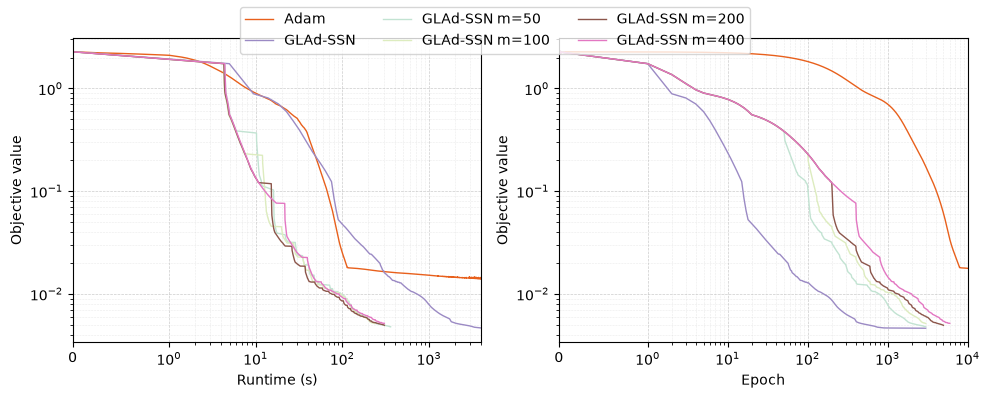

In [22]:
# Uses PLOT_METHODS, PLOT_LINEWIDTH, PLOT_MAX_TIME and PLOT_MAX_ITERATIONS from "Paper-style plots".
# Marker size and spacing also come from PLOT_MARKERSIZE and PLOT_MARKER_SPACING.
# Read the stored objective directly: MSE + the finite-power Hessian-norm penalty.
labels = [label for label in PLOT_METHODS if label in runs.records]
if not labels:
    raise ValueError("Load or run at least one selected method before plotting.")
fig_loss, loss_axes = plt.subplots(1, 2, figsize=(10, 4))
for label in labels:
    history = runs.records[label]["history"]
    color, marker = known_styles.get(label, ("black", "o"))
    loss_axes[0].plot(history["time"], history["loss"], label=label, color=color, linewidth=PLOT_LINEWIDTH,
                      marker=marker, markersize=PLOT_MARKERSIZE, markevery=PLOT_MARKER_SPACING)
    loss_axes[1].plot(history["loss"], label=label, color=color, linewidth=PLOT_LINEWIDTH,
                      marker=marker, markersize=PLOT_MARKERSIZE, markevery=PLOT_MARKER_SPACING)
for ax in loss_axes:
    ax.set_yscale("symlog", linthresh=1e-12)
    ax.set_xscale("symlog", linthresh=1)
    ax.set_ylabel("Objective value")
    ax.xaxis.set_minor_locator(SymmetricalLogLocator(base=10, linthresh=1, subs=range(2, 10)))
    ax.yaxis.set_minor_locator(SymmetricalLogLocator(base=10, linthresh=1e-12, subs=range(2, 10)))
    ax.set_axisbelow(True)
    ax.grid(True, which="major", linestyle="--", linewidth=0.5, alpha=0.65)
    ax.grid(True, which="minor", linestyle="--", linewidth=0.4, alpha=0.25)
loss_axes[0].set_xlabel("Runtime (s)")
loss_axes[1].set_xlabel("Epoch")
loss_axes[0].set_xlim(0, PLOT_MAX_TIME if PLOT_MAX_TIME is not None else
                     max(1, max(runs.records[label]["history"]["time"][-1] for label in labels)))
loss_axes[1].set_xlim(0, PLOT_MAX_ITERATIONS if PLOT_MAX_ITERATIONS is not None else
                     max(1, max(runs.records[label]["info"]["accepted_steps"] for label in labels)))
handles, legend_labels = loss_axes[0].get_legend_handles_labels()
fig_loss.legend(handles, legend_labels, loc="upper center", ncol=3)
fig_loss.tight_layout(rect=[0, 0, 1, 0.95])
if SAVE_FIGURES:
    figure_file = runs.directory() / "plot_NN_new_v2_loss.pdf"
    fig_loss.savefig(figure_file)
    print("Saved:", figure_file)
plt.show()
